# Relay ticket classifier (S1-10, S1-16)

Relay sends each staff request at Kopano Freight to **HR, IT, Finance or Operations** automatically.
This notebook trains that classifier and exports it for the app.

**Model:** TF-IDF + logistic regression (scikit-learn). Fast, small, and easy to explain: every word has a weight per department.

**Data:**
- **Real:** 47,837 IT service tickets from Kaggle, mapped to the four departments (S1-02).
- **Synthetic:** 4,800 Kopano Freight tickets about depots, trucks, fuel cards and payslips (S1-06).

**Target:** at least **85% accuracy on real tickets the model has never seen**, reported separately from synthetic tickets.

**Runs in Google Colab:** *Runtime → Run all*. The first cell downloads the team repo, so no uploads are needed.
The same steps are in `ml/train_classifier.py` for anyone who prefers a script.

## 1. Get the data

In [1]:
# In Colab, download the Relay repo (it's public). On a laptop, run this notebook
# from inside the repo and it uses the files that are already there.
import os

if os.path.exists("../../data/processed/tickets_mapped.csv"):
    os.chdir("../..")  # opened from ml/notebooks inside the repo
elif not os.path.exists("data/processed/tickets_mapped.csv"):
    if not os.path.exists("relay"):
        !git clone --depth 1 https://github.com/mngadisamu/relay.git
    os.chdir("relay")
print("Working in:", os.getcwd())

Working in: /tmp/claude-0/-home-claude/d62ef9eb-64a5-5030-a41a-cbe6690770f9/scratchpad/fix-all


In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

CLASSES = ["Finance", "HR", "IT", "Operations"]
SEED = 42  # fixed, so every run gives the same model

real = pd.read_csv("data/processed/tickets_mapped.csv")
real = pd.DataFrame({"text": real["Document"].fillna(""), "department": real["department"], "source": "real"})

syn = pd.read_csv("data/processed/synthetic_tickets.csv")
syn = pd.DataFrame({
    "text": syn["subject"] + ". " + syn["description"],
    "department": syn["department"],
    "source": "synthetic",
    "scenario_id": syn["scenario_id"],
})

pd.DataFrame({"real": real["department"].value_counts(), "synthetic": syn["department"].value_counts()}).fillna(0).astype(int)

Matplotlib is building the font cache; this may take a moment.


,real,synthetic
department,,
Finance,2924,1200
HR,11612,1440
IT,30862,720
Operations,2439,1440


The real data is mostly IT. HR, Finance and Operations come from keyword rules (`data/scripts/map_departments.py`),
and the synthetic tickets add the Kopano Freight language the Kaggle tickets don't have.

In [3]:
print("Real example:     ", real["text"].iloc[3][:110])
print("Synthetic example:", syn["text"].iloc[1300][:110])

Real example:      reset passwords for external accounts re expire days hi ask help update passwords colleagues thank pm expire d
Synthetic example: Starter paperwork. A new driver starts at the Pomona depot on Monday. What paperwork does he need?


## 2. Hold back tickets for a fair test

- **Real tickets:** 20% are kept aside and never used for training (same department mix).
- **Synthetic tickets:** whole *kinds* of request (two scenarios per department) are kept aside.
  Holding back single tickets would be too easy, because they're written from templates and the model would just recognise the sentences.

In [4]:
real_train, real_test = train_test_split(real, test_size=0.2, stratify=real["department"], random_state=SEED)

rng = np.random.default_rng(SEED)
held_out = []
for dept in CLASSES:
    ids = sorted(syn.loc[syn["department"] == dept, "scenario_id"].unique())
    held_out += list(rng.choice(ids, size=2, replace=False))
syn_test = syn[syn["scenario_id"].isin(held_out)]
syn_train = syn[~syn["scenario_id"].isin(held_out)]

train = pd.concat([real_train, syn_train], ignore_index=True)
print(f"Training on {len(train)} tickets; testing on {len(real_test)} real and {len(syn_test)} synthetic tickets it never sees.")

Training on 42109 tickets; testing on 9568 real and 960 synthetic tickets it never sees.


## 3. Train

**TF-IDF** turns each ticket into numbers: words that are common in one ticket but rare overall (like *payslip* or *forklift*) get high weights.
Single words and word pairs are used, so *fuel card* counts as one idea.

**Logistic regression** learns a weight for every word per department.
`class_weight="balanced"` makes each Finance or Operations ticket count for more, because there are far fewer of them than IT tickets.

These settings are saved into the exported JSON, so the TypeScript code in the app prepares text exactly the same way.

In [5]:
PREPROCESSING = {
    "lowercase": True,
    "token_pattern": r"\b[a-z][a-z]+\b",  # words of 2+ letters
    "ngram_range": [1, 2],
    "stop_words": None,
    "sublinear_tf": True,
    "norm": "l2",
}

vectorizer = TfidfVectorizer(
    lowercase=True,
    token_pattern=r"(?u)" + PREPROCESSING["token_pattern"],
    ngram_range=(1, 2),
    sublinear_tf=True,
    norm="l2",
    min_df=3,
    max_features=40000,
)
X_train = vectorizer.fit_transform(train["text"])
model = LogisticRegression(max_iter=3000, class_weight="balanced", C=4.0)
model.fit(X_train, train["department"])
print("Words and word pairs learned:", len(vectorizer.vocabulary_))

Words and word pairs learned: 40000


## 4. Results on real tickets it has never seen (target: 85%)

Real tickets: accuracy 90.0% on 9568 tickets

              precision    recall  f1-score   support

     Finance       0.89      0.84      0.86       585
          HR       0.84      0.86      0.85      2322
          IT       0.94      0.92      0.93      6173
  Operations       0.76      0.86      0.80       488

    accuracy                           0.90      9568
   macro avg       0.86      0.87      0.86      9568
weighted avg       0.90      0.90      0.90      9568



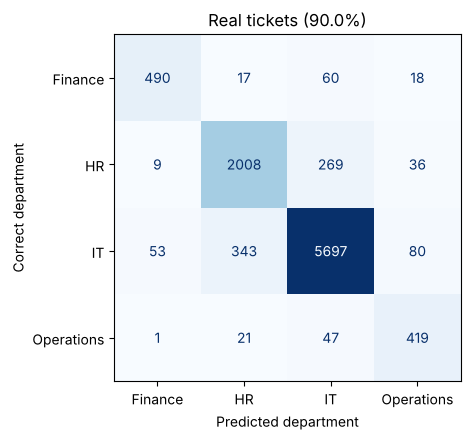

In [6]:
def evaluate(name, df):
    pred = model.predict(vectorizer.transform(df["text"]))
    acc = accuracy_score(df["department"], pred)
    print(f"{name}: accuracy {acc:.1%} on {len(df)} tickets\n")
    print(classification_report(df["department"], pred, labels=CLASSES, zero_division=0))
    cm = confusion_matrix(df["department"], pred, labels=CLASSES)
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name} ({acc:.1%})")
    ax.set_xlabel("Predicted department")
    ax.set_ylabel("Correct department")
    plt.tight_layout()
    plt.show()
    return acc

acc_real = evaluate("Real tickets", real_test)

**How to read the confusion matrix:** each row is the correct department and each column is what the model chose.
The diagonal is right; everything else is a mistake. Most mistakes are between HR and IT, because many Kaggle IT tickets
are about new starters and access, which sound like HR.

## 5. Results on synthetic tickets from unseen kinds of request

Synthetic tickets (unseen scenarios): accuracy 68.6% on 960 tickets

              precision    recall  f1-score   support

     Finance       1.00      0.62      0.76       240
          HR       1.00      0.71      0.83       240
          IT       0.45      0.85      0.59       240
  Operations       0.72      0.57      0.64       240

    accuracy                           0.69       960
   macro avg       0.79      0.69      0.71       960
weighted avg       0.79      0.69      0.71       960



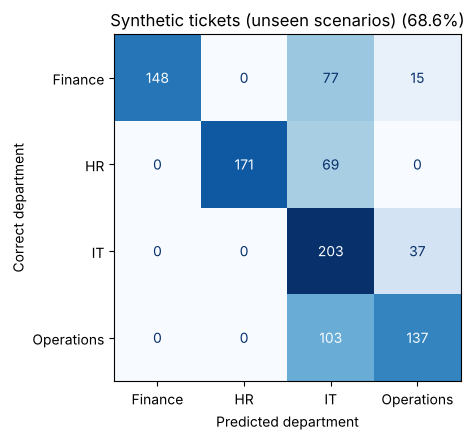

In [7]:
acc_syn = evaluate("Synthetic tickets (unseen scenarios)", syn_test)

This is a harder test: the model has never seen these kinds of request at all, only other kinds.
It's lower than the real-ticket score, which is why every ticket under 60% confidence is marked **Needs review**
and agents can move a ticket to the right department (S1-25).

## 6. Try it on Kopano Freight requests

In [8]:
examples = [
    "My payslip is wrong",
    "Fuel card declined at the pump, I paid for diesel myself",
    "Forklift at City Deep needs a service",
    "Truck broke down on the route to Pomona",
    "Laptop won't switch on after the update",
    "Reflective vest replacement",
]
probs = model.predict_proba(vectorizer.transform(examples))
pd.DataFrame({
    "request": examples,
    "department": model.classes_[probs.argmax(1)],
    "confidence": probs.max(1).round(2),
    "needs review (< 0.6)": probs.max(1) < 0.6,
})

,request,department,confidence,needs review (< 0.6)
0,My payslip is wrong,HR,0.88,False
1,"Fuel card declined at the pump, I paid for die...",Finance,0.44,True
2,Forklift at City Deep needs a service,Operations,0.72,False
3,Truck broke down on the route to Pomona,Operations,0.99,False
4,Laptop won't switch on after the update,IT,1.00,False
5,Reflective vest replacement,Operations,0.50,True


## 7. Export for the app

The scores above came from held-out tickets. For the model the app uses, it's trained once more on **every** ticket, so nothing is wasted,
then saved as `ml/model/classifier-model.json`. `src/lib/classifier.ts` repeats the same maths in TypeScript and answers in under a millisecond.

In [9]:
all_tickets = pd.concat([real, syn], ignore_index=True)
X_all = vectorizer.fit_transform(all_tickets["text"])
model.fit(X_all, all_tickets["department"])

export = {
    "version": "tfidf-logreg-v2",
    "classes": CLASSES,
    "preprocessing": PREPROCESSING,
    "vocabulary": {t: int(i) for t, i in vectorizer.vocabulary_.items()},
    "idf": [round(float(x), 5) for x in vectorizer.idf_],
    "coef": [[round(float(x), 5) for x in row] for row in model.coef_],
    "intercept": [round(float(x), 5) for x in model.intercept_],
    "metrics": {"accuracy_real": round(acc_real, 4), "accuracy_synthetic": round(acc_syn, 4)},
}
out = Path("ml/model/classifier-model.json")
out.write_text(json.dumps(export, separators=(",", ":")), encoding="utf-8")
print(f"Saved {out} ({out.stat().st_size / 1e6:.1f} MB, {len(export['vocabulary'])} terms)")

Saved ml/model/classifier-model.json (2.5 MB, 40000 terms)


## Responsible AI notes

- **Labels are partly rules:** HR, Finance and Operations labels in the real data come from keyword rules, so their scores partly measure how well the model learned the rules.
- **Synthetic data is tidy:** synthetic tickets are cleaner than real Kopano Freight requests will be.
- **People stay in control:** low-confidence tickets are flagged for review, agents can reroute any ticket, and every routing decision and override is saved (`classifications`, `audit_log`). Those corrections are the best training data for the next model.